# Lab 9 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab09.py`
and draws the three figures for your report. It therefore only runs once your implementation
is correct. Export the figures (right-click, or `plt.savefig`) and embed them in `report.pdf`.

In [1]:
import sys
sys.path.insert(0, '../src')
import matplotlib.pyplot as plt
import numpy as np
import torch
import lab09

data = lab09.load_data('../data/lab09_ring.npz')
art = {}                                # run_experiment stores samples/curves here
rng = torch.Generator().manual_seed(lab09.SEED)
metrics = lab09.run_experiment(data, rng, out=art)   # about 10 s on CPU
{k: v for k, v in metrics.items() if not isinstance(v, list)}

{'n_train': 2000,
 'n_gen': 2000,
 'coverage_gan': 6,
 'coverage_ddpm': 8,
 'hq_gan': 0.9375,
 'hq_ddpm': 0.856,
 'd_loss_final': 1.3018,
 'g_loss_final': 1.1204,
 'ddpm_loss_final': 0.245,
 'gan_sample_seconds': 0.0004,
 'ddpm_sample_seconds': 0.121}

## Plot 1 — Real data vs GAN samples vs DDPM samples

Three scatter panels side by side, same axis limits. Mark the true `mode_centers`
(e.g., black crosses) on every panel: a cross with no cloud around it is a mode
that model did not produce.

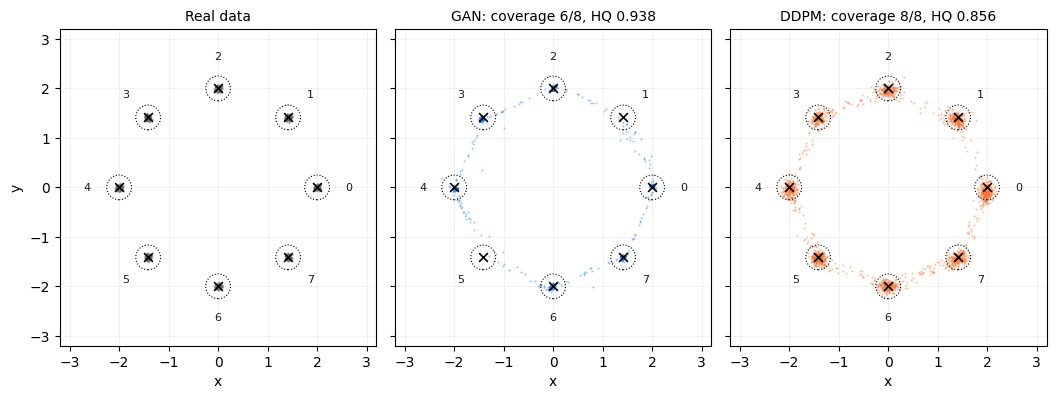

In [2]:
# ============ Plot 1 ============
import os
os.makedirs('../figures', exist_ok=True)
C_REAL, C_GAN, C_DDPM, C_G = '#666666', '#257de0', '#f47230', '#00b894'
centers = data['mode_centers']
panels = [('Real data', data['samples'], C_REAL, None),
          ('GAN', art['samples_gan'], C_GAN, 'gan'),
          ('DDPM', art['samples_ddpm'], C_DDPM, 'ddpm')]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, (name, pts, color, key) in zip(axes, panels):
    ax.scatter(pts[:, 0], pts[:, 1], s=2, color=color, alpha=0.45, linewidths=0)
    ax.scatter(centers[:, 0], centers[:, 1], marker='x', s=40, color='black',
               linewidths=1.2, zorder=3)
    for k, (cx, cy) in enumerate(centers):
        ax.add_patch(plt.Circle((cx, cy), lab09.HQ_RADIUS, fill=False, ls=':',
                                lw=0.8, color='black'))
        ax.text(1.32 * cx, 1.32 * cy, str(k), ha='center', va='center', fontsize=8,
                color='#191919')
    title = name if key is None else (f"{name}: coverage {metrics['coverage_' + key]}/8, "
                                      f"HQ {metrics['hq_' + key]:.3f}")
    ax.set_title(title, fontsize=10)
    ax.set(xlim=(-3.2, 3.2), ylim=(-3.2, 3.2), aspect='equal', xlabel='x')
    ax.grid(alpha=0.25, lw=0.5)
axes[0].set_ylabel('y')
fig.savefig('../figures/figure1.png', dpi=200, bbox_inches='tight', pad_inches=0.06)
plt.show()


## Plot 2 — Training loss curves

Left: `metrics['gan_d_curve']` and `metrics['gan_g_curve']` (one point per
`LOG_EVERY` = 100 steps). Right: `metrics['ddpm_curve']`. Note how differently
the two trainings "look" while running.

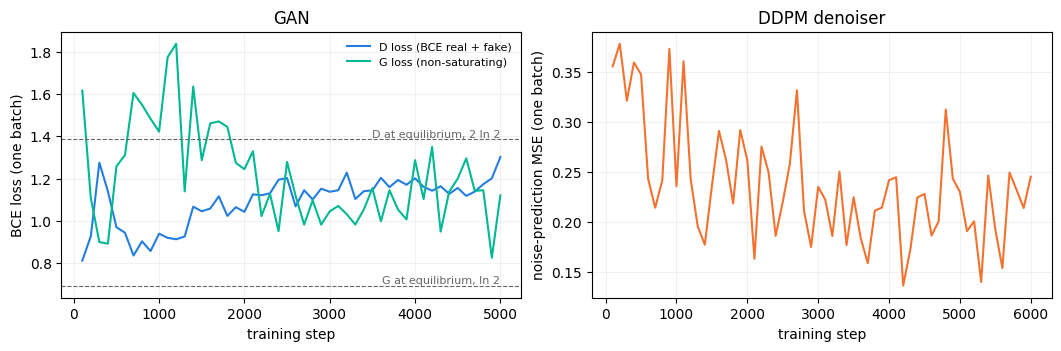

In [3]:
# ============ Plot 2 ============
def steps(c):
    return (np.arange(len(c)) + 1) * lab09.LOG_EVERY

fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 3.4), constrained_layout=True)
a.plot(steps(metrics['gan_d_curve']), metrics['gan_d_curve'], color=C_GAN, lw=1.5,
       label='D loss (BCE real + fake)')
a.plot(steps(metrics['gan_g_curve']), metrics['gan_g_curve'], color=C_G, lw=1.5,
       label='G loss (non-saturating)')
for y, txt in ((2 * np.log(2), 'D at equilibrium, 2 ln 2'), (np.log(2), 'G at equilibrium, ln 2')):
    a.axhline(y, color='#666666', ls='--', lw=0.8)
    a.text(lab09.GAN_STEPS, y, txt, ha='right', va='bottom', fontsize=8, color='#666666')
a.set(title='GAN', xlabel='training step', ylabel='BCE loss (one batch)')
a.legend(fontsize=8, loc='upper right', frameon=False)
b.plot(steps(metrics['ddpm_curve']), metrics['ddpm_curve'], color=C_DDPM, lw=1.5)
b.set(title='DDPM denoiser', xlabel='training step',
      ylabel='noise-prediction MSE (one batch)')
for ax in (a, b):
    ax.grid(alpha=0.25, lw=0.5)
fig.savefig('../figures/figure2.png', dpi=200, bbox_inches='tight', pad_inches=0.06)
plt.show()


## Plot 3 — Per-mode sample share

Grouped bars: `metrics['gan_mode_shares']` vs `metrics['ddpm_mode_shares']` for
modes 0–7, with a horizontal line at `lab09.MODE_SHARE_MIN`. Bars below the
line are the uncovered modes.

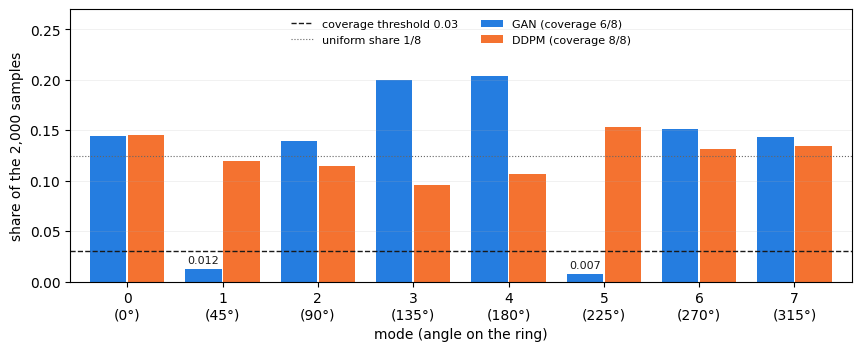

coverage_gan = 6 / coverage_ddpm = 8


In [4]:
# ============ Plot 3 ============
k = np.arange(8)
w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 3.4), constrained_layout=True)
for off, key, color, name in ((-w / 2 - 0.01, 'gan', C_GAN, 'GAN'),
                              (w / 2 + 0.01, 'ddpm', C_DDPM, 'DDPM')):
    shares = metrics[key + '_mode_shares']
    ax.bar(k + off, shares, w, color=color,
           label=f"{name} (coverage {metrics['coverage_' + key]}/8)")
    for i, s in enumerate(shares):
        if s < lab09.MODE_SHARE_MIN:
            ax.text(i + off, s + 0.004, f'{s:.3f}', ha='center', va='bottom', fontsize=8,
                    color='#191919')
ax.axhline(lab09.MODE_SHARE_MIN, color='#191919', ls='--', lw=1,
           label=f'coverage threshold {lab09.MODE_SHARE_MIN}')
ax.axhline(1 / 8, color='#666666', ls=':', lw=0.8, label='uniform share 1/8')
ax.set_xticks(k, [f'{i}\n({45 * i}°)' for i in k])
ax.set(xlabel='mode (angle on the ring)', ylabel='share of the 2,000 samples',
       xlim=(-0.6, 7.6), ylim=(0, 0.27))
ax.legend(fontsize=8, loc='upper center', ncol=2, frameon=False)
ax.grid(axis='y', alpha=0.25, lw=0.5)
fig.savefig('../figures/figure3.png', dpi=200, bbox_inches='tight', pad_inches=0.06)
plt.show()
print('coverage_gan =', metrics['coverage_gan'], '/ coverage_ddpm =', metrics['coverage_ddpm'])
